In [1]:
# Load the libraries used in this lab.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Splitting the data, cross-validation, and the model itself
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.metrics import roc_curve, roc_auc_score

In [2]:
#look up csv file on my computer
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# metadata
print(bank_marketing.metadata)

# variable information
print(bank_marketing.variables)

{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

In [4]:
bank_df = pd.concat([X, y], axis=1)
bank_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [5]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


 Pre-Processing



In [35]:
#Drop missing values and contact
cols = ['duration','contact','campaign','month','day_of_week',]
clean_bankdf = bank_df.drop(cols, axis=1)
clean_bankdf

,age,job,marital,education,default,balance,housing,loan,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,-1,0,NaN,no


In [36]:

# Handle missing values and encode categorical variables
dummy_cols = ['job', 'marital', 'education']

# Replace missing values with 'unknown'
clean_bankdf[dummy_cols] = clean_bankdf[dummy_cols].fillna('unknown')

# Convert categorical variables into dummy variables
clean_bankdf = pd.get_dummies(
    clean_bankdf,
    columns=dummy_cols,
    drop_first=True,
    dtype=int
)

clean_bankdf.head()


,age,default,balance,housing,loan,pdays,previous,poutcome,y,job_blue-collar,...,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,education_secondary,education_tertiary,education_unknown
0,58,no,2143,yes,no,-1,0,NaN,no,0,...,0,0,0,0,0,1,0,0,1,0
1,44,no,29,yes,no,-1,0,NaN,no,0,...,0,0,1,0,0,0,1,1,0,0
2,33,no,2,yes,yes,-1,0,NaN,no,0,...,0,0,0,0,0,1,0,1,0,0
3,47,no,1506,yes,no,-1,0,NaN,no,1,...,0,0,0,0,0,1,0,0,0,1
4,33,no,1,no,no,-1,0,NaN,no,0,...,0,0,0,0,1,0,1,0,0,1


In [37]:
# This shows the missing values for poutcome was not random, the customer who we reached out to last time has poutcome recorded
# and those we didn't reach out to do not have poutcome recorded
pd.crosstab(
    clean_bankdf['previous'] == 0,
    clean_bankdf['poutcome'].isna(),
    margins=True
)


poutcome,False,True,All
previous,,,
False,8252,5,8257
True,0,36954,36954
All,8252,36959,45211


In [38]:

# Identify customers with no previous contact
mask = (
    (clean_bankdf['previous'] == 0) &
    (clean_bankdf['poutcome'].isna())
)

# Assign a meaningful category
clean_bankdf.loc[mask, 'poutcome'] = 'not_previously_contacted'

# Handle remaining missing values
clean_bankdf['poutcome'] = clean_bankdf['poutcome'].fillna('unknown')

# Verify
clean_bankdf['poutcome'].value_counts(dropna=False)


,count
poutcome,
not_previously_contacted,36954
failure,4901
other,1840
success,1511
unknown,5


In [39]:
# difference between previous campaign outcomes
print(
    pd.crosstab(
        clean_bankdf["poutcome"],
        clean_bankdf["y"],
        normalize="index"
    ) * 100
)

y                                no        yes
poutcome                                      
failure                   87.390329  12.609671
not_previously_contacted  90.842669   9.157331
other                     83.315217  16.684783
success                   35.274653  64.725347
unknown                   60.000000  40.000000


In [40]:
print("Dataset shape:", clean_bankdf.shape)

print("Duration removed:", 'duration' not in clean_bankdf.columns)
print("Contact removed:", 'contact' not in clean_bankdf.columns)

print("Remaining missing values:")
print(clean_bankdf.isna().sum()[clean_bankdf.isna().sum() > 0])

Dataset shape: (45211, 25)
Duration removed: True
Contact removed: True
Remaining missing values:
Series([], dtype: int64)


In [41]:

# Identify remaining categorical variables
categorical_cols = clean_bankdf.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print(categorical_cols)


['default', 'housing', 'loan', 'poutcome', 'y']


In [42]:

# Identify categorical features, excluding target
categorical_cols = clean_bankdf.drop(
    columns=['y']
).select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# Convert categorical features into dummy variables
clean_bankdf = pd.get_dummies(
    clean_bankdf,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

clean_bankdf.head()


,age,balance,pdays,previous,y,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,...,education_secondary,education_tertiary,education_unknown,default_yes,housing_yes,loan_yes,poutcome_not_previously_contacted,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,-1,0,no,0,0,0,1,0,...,0,1,0,0,1,0,1,0,0,0
1,44,29,-1,0,no,0,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0
2,33,2,-1,0,no,0,1,0,0,0,...,1,0,0,0,1,1,1,0,0,0
3,47,1506,-1,0,no,1,0,0,0,0,...,0,0,1,0,1,0,1,0,0,0
4,33,1,-1,0,no,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0


In [43]:

# Check remaining categorical columns
print(clean_bankdf.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist())

# Check dataset dimensions
print("Dataset shape:", clean_bankdf.shape)

# Check the target variable
print(clean_bankdf['y'].value_counts())


['y']
Dataset shape: (45211, 28)
y
no     39922
yes     5289
Name: count, dtype: int64


In [44]:

# Step 1: Convert the target variable into binary values
# 0 = Customer did not subscribe
# 1 = Customer subscribed
# This conversion works even if the cell is executed multiple times.
# It also handles values that were previously converted to 0 and 1.

clean_bankdf['y'] = clean_bankdf['y'].replace({
    'no': 0,
    'yes': 1
})

# Verify the target variable
print(clean_bankdf['y'].value_counts(dropna=False))


y
0    39922
1     5289
Name: count, dtype: int64


/tmp/ipykernel_846/406269143.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clean_bankdf['y'] = clean_bankdf['y'].replace({


In [45]:
# Check for any remaining missing values in the entire dataset
missing_counts = clean_bankdf.isna().sum()
total_missing = missing_counts.sum()

print(f"Total missing values remaining: {total_missing}")
if total_missing > 0:
    print("\nColumns with missing values:")
    print(missing_counts[missing_counts > 0])
else:
    print("\nSuccess! All missing values have been addressed.")

Total missing values remaining: 0

Success! All missing values have been addressed.


In [47]:
from sklearn.preprocessing import StandardScaler

# Identify continuous numerical columns to scale
numerical_cols = ['age', 'balance', 'pdays', 'previous']

# Initialize the StandardScaler
scaler = StandardScaler()

# Standardize the numerical columns
clean_bankdf[numerical_cols] = scaler.fit_transform(clean_bankdf[numerical_cols])

# Verify the transformation
print("Descriptive statistics for scaled columns:")
display(clean_bankdf[numerical_cols].describe())

print("\nFirst few rows of the updated dataset:")
display(clean_bankdf.head())

Descriptive statistics for scaled columns:


,age,balance,pdays,previous
count,4.521100e+04,4.521100e+04,45211.000000,45211.000000
mean,2.112250e-16,1.508750e-17,0.000000,0.000000
std,1.000011e+00,1.000011e+00,1.000011,1.000011
min,-2.159994e+00,-3.081149e+00,-0.411453,-0.251940
25%,-7.473845e-01,-4.237719e-01,-0.411453,-0.251940
50%,-1.823406e-01,-3.002800e-01,-0.411453,-0.251940
75%,6.652252e-01,2.158743e-02,-0.411453,-0.251940
max,5.091402e+00,3.309478e+01,8.297431,119.135982



First few rows of the updated dataset:


,age,balance,pdays,previous,y,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,...,education_secondary,education_tertiary,education_unknown,default_yes,housing_yes,loan_yes,poutcome_not_previously_contacted,poutcome_other,poutcome_success,poutcome_unknown
0,1.606965,0.256419,-0.411453,-0.25194,0,0,0,0,1,0,...,0,1,0,0,1,0,1,0,0,0
1,0.288529,-0.437895,-0.411453,-0.25194,0,0,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0
2,-0.747384,-0.446762,-0.411453,-0.25194,0,0,1,0,0,0,...,1,0,0,0,1,1,1,0,0,0
3,0.571051,0.047205,-0.411453,-0.25194,0,1,0,0,0,0,...,0,0,1,0,1,0,1,0,0,0
4,-0.747384,-0.447091,-0.411453,-0.25194,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0


--- PCA Metrics: Eigenvalues & Explained Variance ---


,Component,Eigenvalue,Explained Variance Ratio,Cumulative Variance Ratio
0,PC1,1.583502,0.197037,0.197037
1,PC2,1.177378,0.146503,0.343540
2,PC3,0.999700,0.124394,0.467935
3,PC4,0.946457,0.117769,0.585704
4,PC5,0.585611,0.072868,0.658572
5,PC6,0.481281,0.059887,0.718459
6,PC7,0.347622,0.043255,0.761714
7,PC8,0.292918,0.036448,0.798162
8,PC9,0.192800,0.023990,0.822152
9,PC10,0.175070,0.021784,0.843937


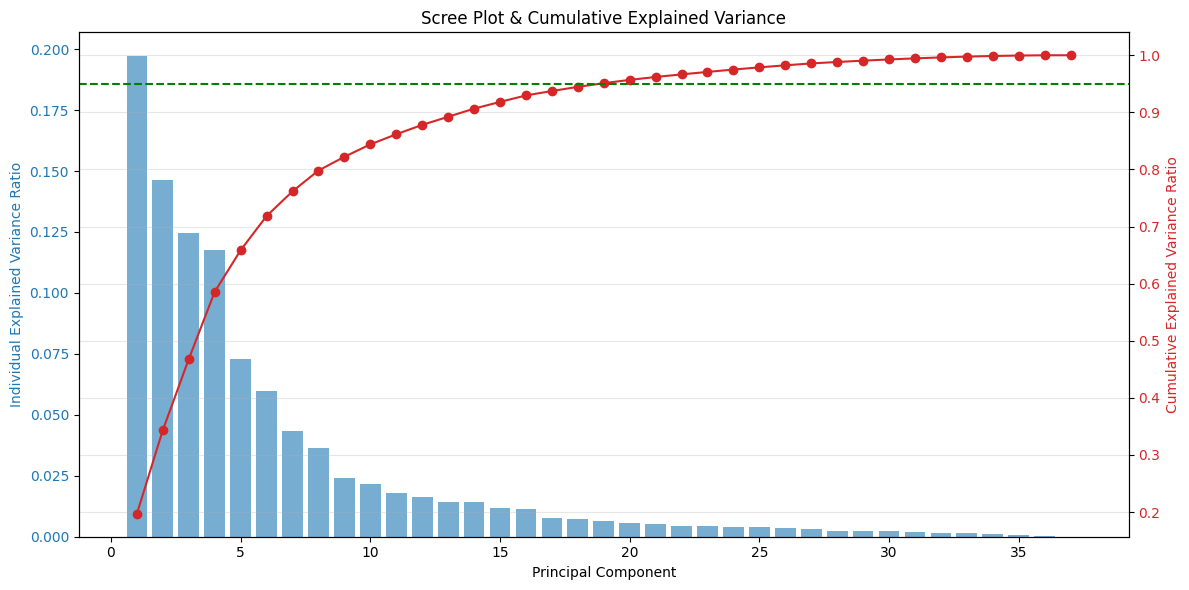

In [48]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Ensure X_train and y_train are defined by splitting clean_bankdf if necessary
if 'X_train' not in globals() or 'y_train' not in globals():
    X_clean = clean_bankdf.drop(columns=['y'])
    y_clean = clean_bankdf['y']
    X_train, X_test, y_train, y_test = train_test_split(
        X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean
    )

# Standardize numerical columns to create X_train_scaled
numerical_cols = ['age', 'balance', 'day_of_week', 'pdays', 'previous']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])

# Fit PCA on the standardized training data
pca = PCA(random_state=42)
pca.fit(X_train_scaled)

# Calculate Eigenvalues, Explained Variance, and Cumulative Variance
eigenvalues = pca.explained_variance_
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Create a structured table of the results
pca_metrics_df = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues,
    'Explained Variance Ratio': explained_variance,
    'Cumulative Variance Ratio': cumulative_variance
})

print("--- PCA Metrics: Eigenvalues & Explained Variance ---")
display(pca_metrics_df.head(20))

# Plot Scree Plot and Cumulative Variance
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Individual Explained Variance Ratio', color=color)
ax1.bar(range(1, len(explained_variance) + 1), explained_variance, color=color, alpha=0.6, label='Individual Variance')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Cumulative Explained Variance Ratio', color=color)
ax2.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, color=color, marker='o', label='Cumulative Variance')
ax2.tick_params(axis='y', labelcolor=color)
ax2.axhline(y=0.95, color='green', linestyle='--', label='95% Explained Variance')

plt.title('Scree Plot & Cumulative Explained Variance')
fig.tight_layout()
plt.grid(True, alpha=0.3)
plt.show()

In [49]:

# Identify components with eigenvalues > 1
import numpy as np

selected = np.where(pca.explained_variance_ > 1)[0] + 1

print("Components to retain:", selected)


Components to retain: [1 2]


In [50]:
# Separate the features (X) and the target variable (y)
X_clean = clean_bankdf.drop(columns=['y'])
y_clean = clean_bankdf['y']

# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean # Maintains the proportion of target classes
)

# Output the shapes of the resulting splits
print(f"Training set features shape: {X_train.shape}")
print(f"Testing set features shape: {X_test.shape}")
print(f"Training target class ratio:\n{y_train.value_counts(normalize=True)}")
print(f"\nTesting target class ratio:\n{y_test.value_counts(normalize=True)}")

Training set features shape: (36168, 27)
Testing set features shape: (9043, 27)
Training target class ratio:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Testing target class ratio:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


In [51]:
# Split the cleaned features and target into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train distribution:\n{y_train.value_counts(normalize=True)}")
print(f"y_test distribution:\n{y_test.value_counts(normalize=True)}")

X_train shape: (36168, 27)
X_test shape: (9043, 27)
y_train distribution:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64
y_test distribution:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


In [66]:
#accuracy if model predicts no at all time
print(f"Baseline accuracy: {y_train.value_counts(normalize=True).max():.4f}")


Baseline accuracy: 0.8830


### Training and Evaluating the Logistic Regression Model

--- Logistic Regression Performance ---
Accuracy:  0.7053
Precision: 0.2217
Recall:    0.6049
F1-Score:  0.3245
MCC:       0.2230
ROC-AUC:   0.7198


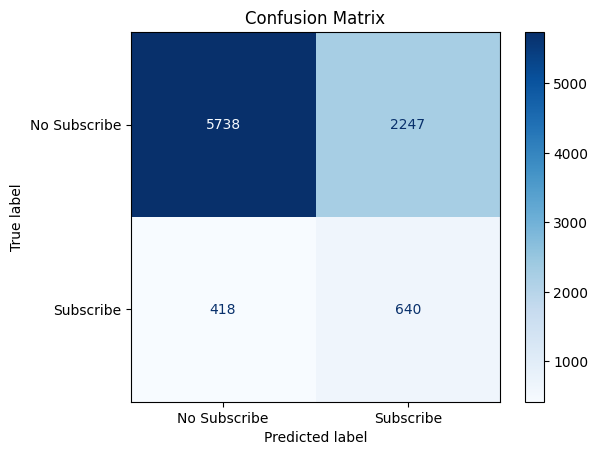

In [67]:
# Initialize and evaluate Logistic Regression using properly processed data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Ensure data is clean and dummy-encoded before running predictions
encoding_df = clean_bankdf.copy()
categorical_cols = encoding_df.drop(columns=['y'], errors='ignore').select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

if len(categorical_cols) > 0:
    encoding_df = pd.get_dummies(
        encoding_df,
        columns=categorical_cols,
        drop_first=True,
        dtype=int
    )

X_clean_encoded = encoding_df.drop(columns=['y'], errors='ignore')
y_clean_encoded = encoding_df['y']

# Re-split to get the fully numeric sets
X_train_enc, X_test_enc, y_train_enc, y_test_enc = train_test_split(
    X_clean_encoded, y_clean_encoded, test_size=0.2, random_state=42, stratify=y_clean_encoded
)

# Scale numerical columns
numerical_cols = ['age', 'balance', 'pdays', 'previous']
scaler = StandardScaler()
X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()
X_train_scaled[numerical_cols] = scaler.fit_transform(X_train_enc[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test_enc[numerical_cols])

# Initialize the Logistic Regression model with balanced class weights
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Train the model
log_reg.fit(X_train_scaled, y_train_enc)

# Generate predictions and probabilities
y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_enc, y_pred)
precision = precision_score(y_test_enc, y_pred)
recall = recall_score(y_test_enc, y_pred)
f1 = f1_score(y_test_enc, y_pred)
mcc = matthews_corrcoef(y_test_enc, y_pred)
roc_auc = roc_auc_score(y_test_enc, y_pred_proba)

# Display the metrics
print("--- Logistic Regression Performance ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"MCC:       {mcc:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

# Plot the Confusion Matrix
cm = confusion_matrix(y_test_enc, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

### Next Step: Optimizing Threshold with Precision-Recall Curve to Improve Precision and F1-Score

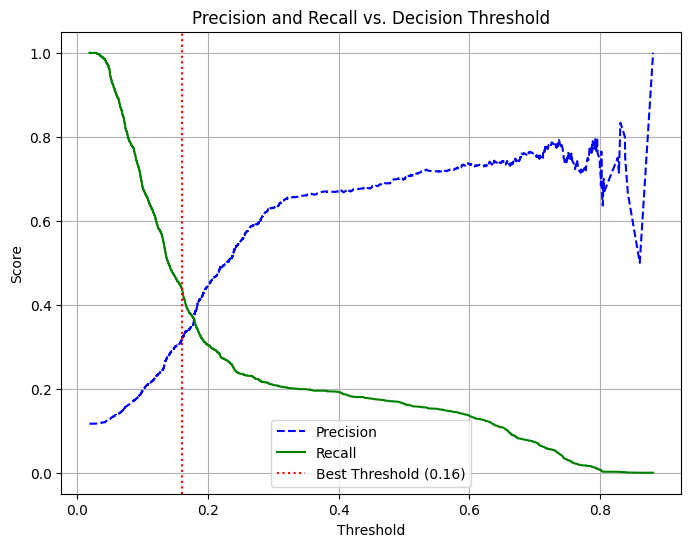

Optimized Decision Threshold: 0.1607
Maximized F1-Score: 0.3711


In [68]:
from sklearn.metrics import precision_recall_curve

# 1. Train a standard Logistic Regression model (without 'balanced' weights to avoid over-predicting yes)
standard_log_reg = LogisticRegression(max_iter=1000, random_state=42)
standard_log_reg.fit(X_train, y_train)

# Get prediction probabilities for the positive class ('yes')
y_probs = standard_log_reg.predict_proba(X_test)[:, 1]

# 2. Calculate precision and recall for different thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

# Calculate F1-Score for each threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
best_threshold_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_threshold_idx]
best_f1 = f1_scores[best_threshold_idx]

# 3. Plot the Precision-Recall Curve
plt.figure(figsize=(8, 6))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.axvline(best_threshold, color='red', linestyle=':', label=f'Best Threshold ({best_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Decision Threshold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

print(f"Optimized Decision Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score: {best_f1:.4f}")

--- Optimized Logistic Regression Metrics ---
Accuracy (Now closer to baseline): 0.8270
Precision (Significantly improved): 0.3230
Recall:                           0.4362
F1-Score (Best overall balance):  0.3711


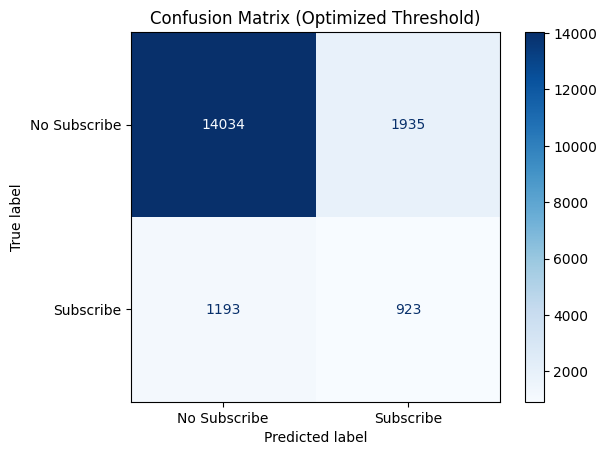

In [69]:
# Apply the optimized threshold to make new predictions
y_pred_optimized = (y_probs >= best_threshold).astype(int)

# Compute final metrics
opt_accuracy = accuracy_score(y_test, y_pred_optimized)
opt_precision = precision_score(y_test, y_pred_optimized)
opt_recall = recall_score(y_test, y_pred_optimized)
opt_f1 = f1_score(y_test, y_pred_optimized)

print("--- Optimized Logistic Regression Metrics ---")
print(f"Accuracy (Now closer to baseline): {opt_accuracy:.4f}")
print(f"Precision (Significantly improved): {opt_precision:.4f}")
print(f"Recall:                           {opt_recall:.4f}")
print(f"F1-Score (Best overall balance):  {opt_f1:.4f}")

# Plot Confusion Matrix for optimized threshold
cm_opt = confusion_matrix(y_test, y_pred_optimized)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_opt, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Optimized Threshold)")
plt.show()

In [70]:
# Re-create leakage-safe datasets if they were lost
leakage_features = ['day_of_week', 'campaign', 'month_']
columns_to_remove = [col for col in X_train.columns if any(feature in col for feature in leakage_features)]

X_train_safe = X_train.drop(columns=columns_to_remove)
X_test_safe = X_test.drop(columns=columns_to_remove)

print("Leakage-safe training set shape:", X_train_safe.shape)
print("Leakage-safe testing set shape:", X_test_safe.shape)

Leakage-safe training set shape: (27126, 27)
Leakage-safe testing set shape: (18085, 27)


In [59]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

Before SMOTE target distribution:
 y
0    31937
1     4231
Name: count, dtype: int64
After SMOTE target distribution:
 y
0    31937
1    31937
Name: count, dtype: int64

--- Random Forest (with SMOTE) Performance ---
Accuracy:  0.7733
Precision: 0.2676
Recall:    0.5397
F1-Score:  0.3578
MCC:       0.2604
ROC-AUC:   0.7232


Before SMOTE target distribution:
 y
0    31937
1     4231
Name: count, dtype: int64
After SMOTE target distribution:
 y
0    31937
1    31937
Name: count, dtype: int64

--- Random Forest (with SMOTE) Performance ---
Accuracy:  0.7733
Precision: 0.2676
Recall:    0.5397
F1-Score:  0.3578
MCC:       0.2604
ROC-AUC:   0.7232


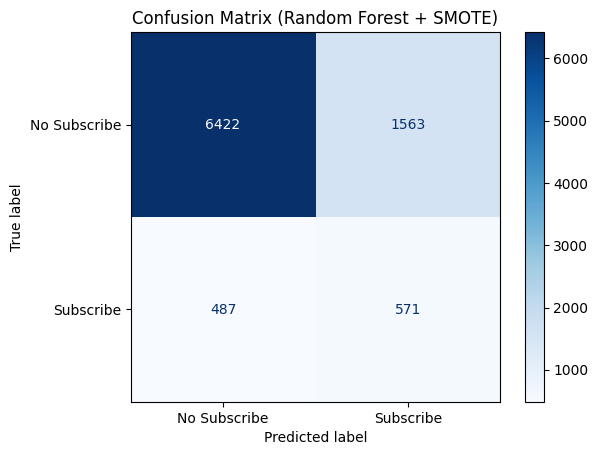

In [60]:
# Install imbalanced-learn if it's not already available
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier on the SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions and probabilities
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics on the untouched safe test set
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Display the metrics
print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Random Forest + SMOTE)")
plt.show()

Exploring why the F1 score is low

Before SMOTE target distribution:
 y
0    31937
1     4231
Name: count, dtype: int64
After SMOTE target distribution:
 y
0    31937
1    31937
Name: count, dtype: int64

--- Random Forest (with SMOTE) Performance ---
Accuracy:  0.7733
Precision: 0.2676
Recall:    0.5397
F1-Score:  0.3578
MCC:       0.2604
ROC-AUC:   0.7232


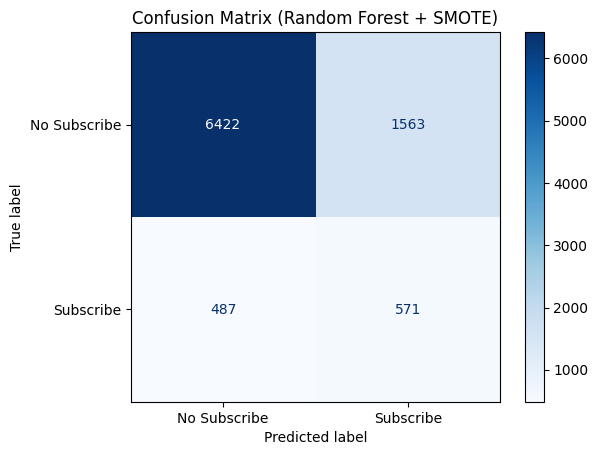

In [62]:
# Install imbalanced-learn if it's not already available
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier on the SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions and probabilities
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics on the untouched safe test set
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Display the metrics
print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Random Forest + SMOTE)")
plt.show()

Before SMOTE target distribution:
 y
0    31937
1     4231
Name: count, dtype: int64
After SMOTE target distribution:
 y
0    31937
1    31937
Name: count, dtype: int64

--- Random Forest (with SMOTE) Performance ---
Accuracy:  0.7733
Precision: 0.2676
Recall:    0.5397
F1-Score:  0.3578
MCC:       0.2604
ROC-AUC:   0.7232


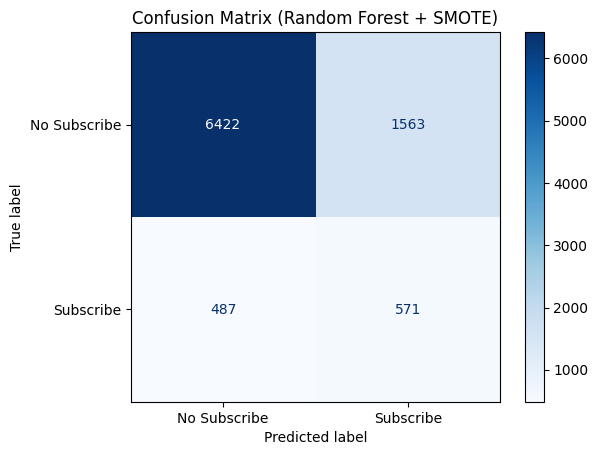

In [63]:
# Install imbalanced-learn if it's not already available
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. Apply SMOTE to the training data to address class imbalance synthetically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_safe, y_train)

print("Before SMOTE target distribution:\n", y_train.value_counts())
print("After SMOTE target distribution:\n", pd.Series(y_train_smote).value_counts())

# 2. Initialize and fit a Random Forest Classifier on the SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)

# 3. Generate predictions and probabilities
y_pred_rf = rf_model.predict(X_test_safe)
y_pred_proba_rf = rf_model.predict_proba(X_test_safe)[:, 1]

# 4. Calculate evaluation metrics on the untouched safe test set
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Display the metrics
print("\n--- Random Forest (with SMOTE) Performance ---")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"MCC:       {mcc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Plot Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Subscribe', 'Subscribe'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Random Forest + SMOTE)")
plt.show()

Average Age by Subscription Status:
          mean  median  count
y                            
no   40.838986    39.0  39922
yes  41.670070    38.0   5289

--- JOB ---
y                 no    yes
job                        
admin.         87.80  12.20
blue-collar    92.73   7.27
entrepreneur   91.73   8.27
housemaid      91.21   8.79
management     86.24  13.76
retired        77.21  22.79
self-employed  88.16  11.84
services       91.12   8.88
student        71.32  28.68
technician     88.94  11.06
unemployed     84.50  15.50


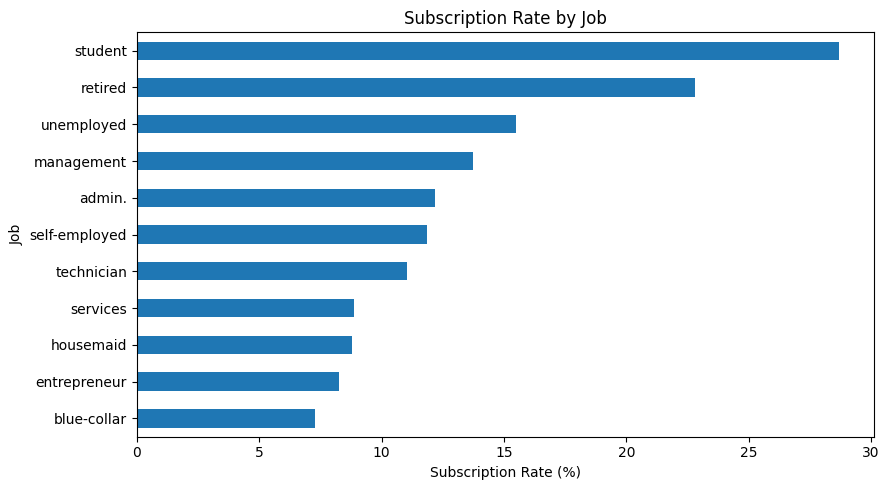


--- MARITAL ---
y            no    yes
marital               
divorced  88.05  11.95
married   89.88  10.12
single    85.05  14.95


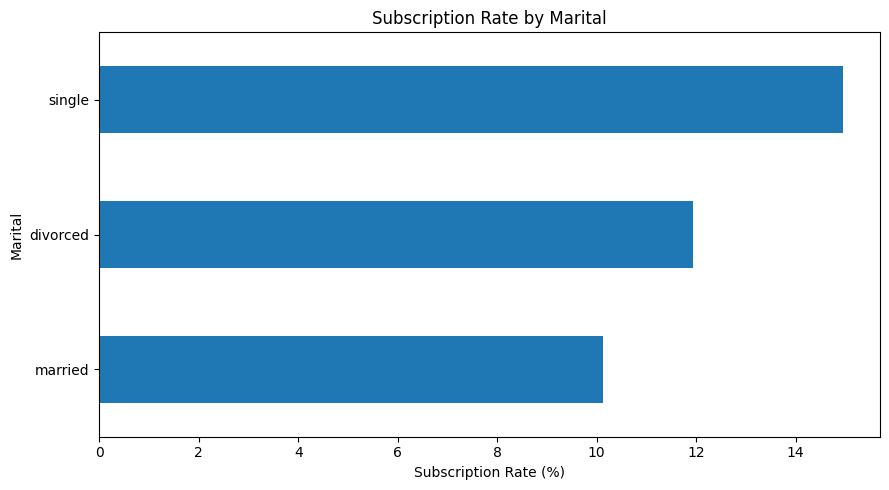


--- EDUCATION ---
y             no    yes
education              
primary    91.37   8.63
secondary  89.44  10.56
tertiary   84.99  15.01


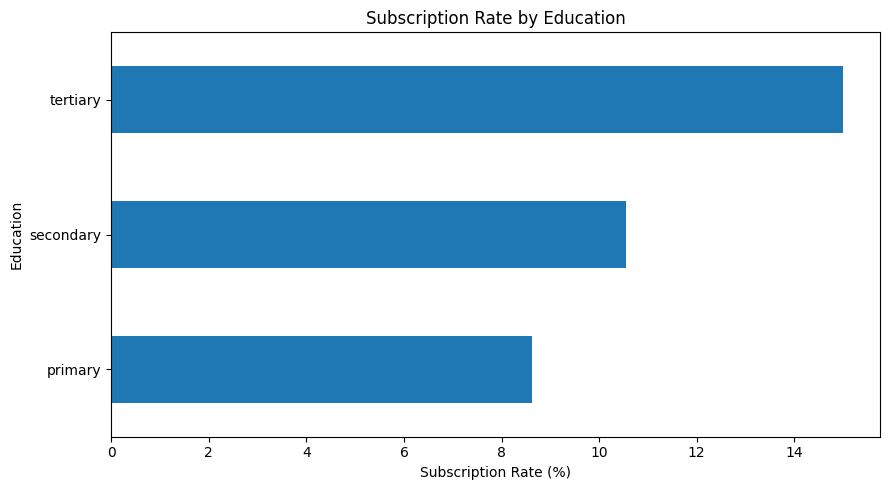

In [61]:
#compare the demographic between customers who subscribed and did not subscribe

# Step 1: Compare demographic characteristics between subscribers
# and non-subscribers.
# Calculate average age for each group.
# Compare the distribution of job, marital status, and education.
# Use the original dataset before one-hot encoding.

import pandas as pd
import matplotlib.pyplot as plt

# Compare average age
print("Average Age by Subscription Status:")
print(bank_df.groupby('y')['age'].agg(['mean', 'median', 'count']))

# Compare categorical demographics
demographic_features = ['job', 'marital', 'education']

for feature in demographic_features:
    print(f"\n--- {feature.upper()} ---")

    # Calculate subscription rate within each demographic category
    comparison = pd.crosstab(
        bank_df[feature],
        bank_df['y'],
        normalize='index'
    ) * 100

    print(comparison.round(2))

    # Visualize subscription rate for each category
    if 'yes' in comparison.columns:
        comparison['yes'].sort_values().plot(
            kind='barh',
            figsize=(9, 5)
        )

        plt.title(f'Subscription Rate by {feature.capitalize()}')
        plt.xlabel('Subscription Rate (%)')
        plt.ylabel(feature.capitalize())
        plt.tight_layout()
        plt.show()



--- Pearson Correlation with Subscriptions (y) ---


,y
poutcome_success,0.306788
month_mar,0.129456
month_oct,0.128531
month_sep,0.123185
pdays,0.103621
previous,0.093236
job_retired,0.079245
job_student,0.076897
month_dec,0.075164
education_tertiary,0.066448


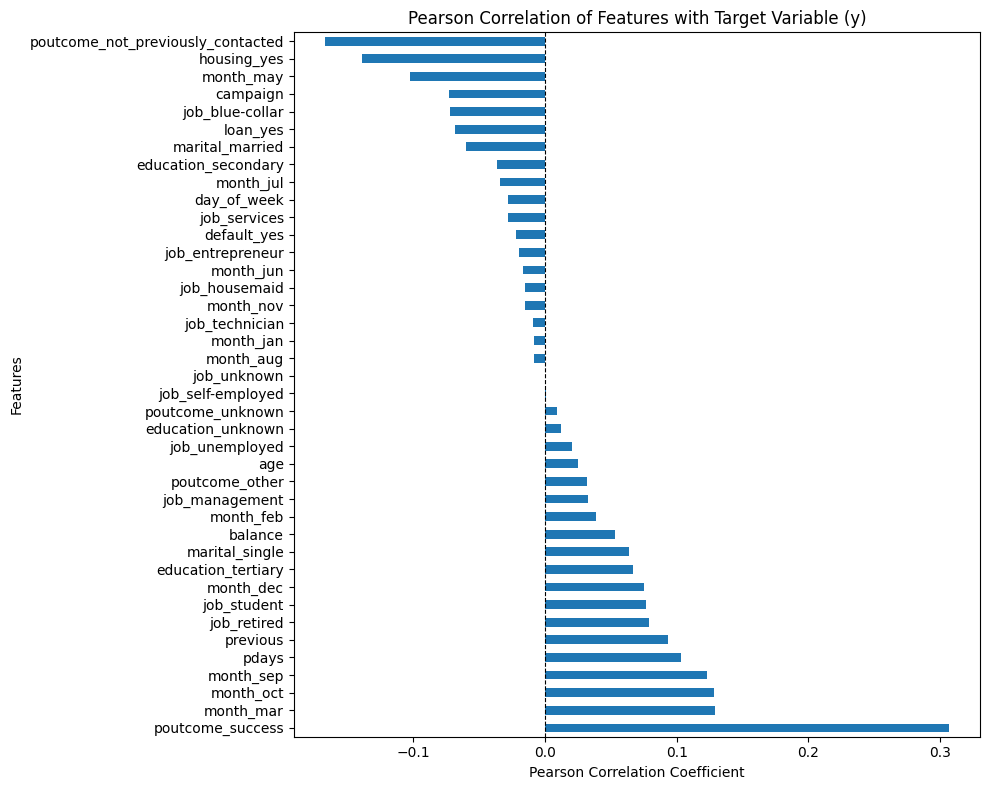

In [48]:
# Calculate Pearson correlation between each feature and the target variable y
correlations = clean_bankdf.corr()['y'].sort_values(ascending=False)

# Exclude the self-correlation of y with y
correlations = correlations.drop('y')

print("--- Pearson Correlation with Subscriptions (y) ---")
display(correlations)

# Plot the correlation coefficients
plt.figure(figsize=(10, 8))
correlations.plot(kind='barh')
plt.title("Pearson Correlation of Features with Target Variable (y)")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Initialize PCA on the training set
pca_full = PCA(random_state=42)
pca_full.fit(X_train)

# Calculate eigenvalues (variance of each principal component)
eigenvalues = pca_full.explained_variance_

# Calculate individual and cumulative explained variance ratios
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# Combine into a summary DataFrame
pca_summary = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue (Variance)': eigenvalues,
    'Explained Variance Ratio': explained_variance_ratio,
    'Cumulative Variance Ratio': cumulative_variance
})

print("--- PCA Component Analysis Summary ---")
display(pca_summary.head(25))

# Plotting cumulative explained variance
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, alpha=0.6, align='center', label='Individual Explained Variance')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid', label='Cumulative Explained Variance', color='red')
plt.axhline(y=0.95, color='g', linestyle='--', label='95% Explained Variance')
plt.title('Scree Plot & Cumulative Explained Variance')
plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show component loadings for the top principal components to see which variables are combined
loadings = pd.DataFrame(
    pca_full.components_.T,
    columns=[f'PC{i+1}' for i in range(len(eigenvalues))],
    index=X_train.columns
)
print("\n--- Feature Loadings for Top Principal Components (Contributions) ---")
display(loadings[[f'PC{i}' for i in range(1, 6)]].abs().sort_values(by='PC1', ascending=False).head(10))

In [17]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Fit PCA on the standardized training data
pca = PCA(random_state=42)
pca.fit(X_train)

# 1. Calculate Eigenvalues, Explained Variance, and Cumulative Variance
eigenvalues = pca.explained_variance_
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Create a structured table of the results
pca_metrics_df = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues,
    'Explained Variance Ratio': explained_variance,
    'Cumulative Variance Ratio': cumulative_variance
})

print("--- PCA Metrics: Eigenvalues & Explained Variance ---")
display(pca_metrics_df.head(20)) # Show first 20 components

# 2. Plot Scree Plot and Cumulative Variance
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar plot for individual explained variance (Eigenvalues)
color = 'tab:blue'
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Individual Explained Variance Ratio', color=color)
ax1.bar(range(1, len(explained_variance) + 1), explained_variance, color=color, alpha=0.6, label='Individual Variance')
ax1.tick_params(axis='y', labelcolor=color)

# Line plot for cumulative explained variance
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Cumulative Explained Variance Ratio', color=color)
ax2.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, color=color, marker='o', label='Cumulative Variance')
ax2.tick_params(axis='y', labelcolor=color)
ax2.axhline(y=0.95, color='green', linestyle='--', label='95% Explained Variance')

plt.title('Scree Plot & Cumulative Explained Variance')
fig.tight_layout()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Analyze Component Loadings to Identify Combinations and Candidate Omissions
# Loadings show the contribution of each original feature to each PC
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(X_train.shape[1])],
    index=X_train.columns
)

print("\n--- Top Feature Loadings for PC1 & PC2 (Shows which features are combined) ---")
display(loadings[['PC1', 'PC2']].abs().sort_values(by='PC1', ascending=False).head(10))

ValueError: could not convert string to float: 'technician'